In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
import pandas as pd

df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


## Random Forest Classifier

A random forest combines many decision trees to predict whether each profile is labeled Low, Medium, or High synthetic layoff risk. We will evaluate it on a held-out test set.

In [54]:
TRAIN, TEST = train_test_split(df, train_size=0.8, random_state=42)

X_train = TRAIN.drop(columns="Layoff_Risk")
y_train = TRAIN["Layoff_Risk"]

X_test = TEST.drop(columns="Layoff_Risk")
y_test = TEST["Layoff_Risk"]

In [56]:
cat_cols = X_train.select_dtypes(include="str").columns
num_cols = X_train.select_dtypes(include="number").columns

# One-hot encode text columns. Random Forest does not need scaled numeric features.
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols),
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )),
])

model.fit(X_train, y_train)
print("Random Forest test accuracy:", model.score(X_test, y_test))

Random Forest test accuracy: 0.90575


In [58]:
# Baseline: always predicts the most common training category
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Baseline test accuracy:", baseline.score(X_test, y_test))

Baseline test accuracy: 0.34375


In [60]:
from sklearn.metrics import classification_report, confusion_matrix

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

print("Training results:")
print(classification_report(y_train, train_predictions, zero_division=0))
print("Training confusion matrix:")
print(confusion_matrix(y_train, train_predictions, labels=rf_model.classes_))

print("\nTest results:")
print(classification_report(y_test, test_predictions, zero_division=0))
print("Test confusion matrix:")
print(confusion_matrix(y_test, test_predictions, labels=rf_model.classes_))

Training results:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00      5422
         Low       1.00      1.00      1.00      5306
      Medium       1.00      1.00      1.00      5272

    accuracy                           1.00     16000
   macro avg       1.00      1.00      1.00     16000
weighted avg       1.00      1.00      1.00     16000

Training confusion matrix:


AttributeError: 'RandomForestClassifier' object has no attribute 'classes_'

In [15]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
print(classification_report(y_test, baseline_predictions, zero_division=0))

              precision    recall  f1-score   support

        High       0.34      1.00      0.51      1360
         Low       0.00      0.00      0.00      1320
      Medium       0.00      0.00      0.00      1320

    accuracy                           0.34      4000
   macro avg       0.11      0.33      0.17      4000
weighted avg       0.12      0.34      0.17      4000



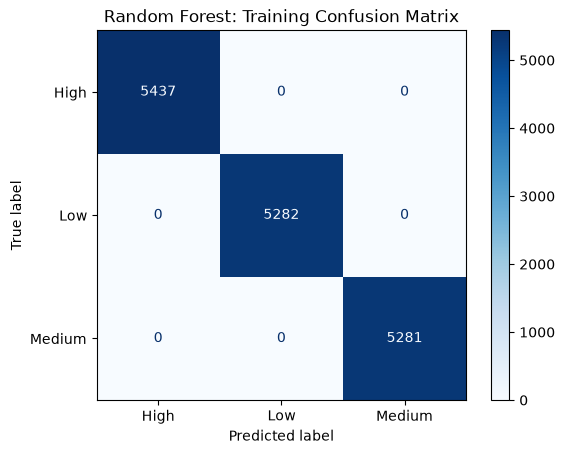

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_train,
    train_predictions,
    labels=rf_model.classes_,
    display_labels=rf_model.classes_,
    cmap="Blues"
)

plt.title("Random Forest: Training Confusion Matrix")
plt.show()

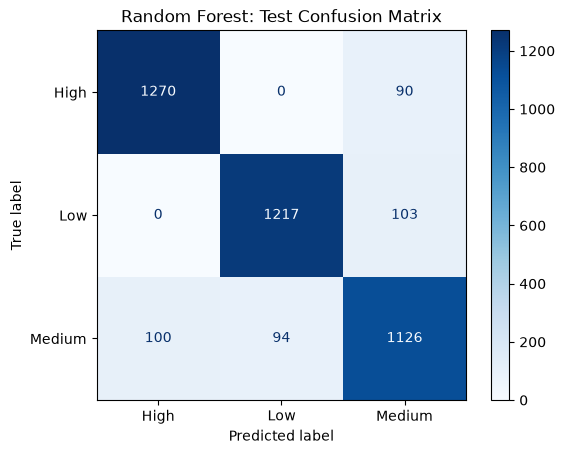

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=rf_model.classes_,
    display_labels=rf_model.classes_,
    cmap="Blues"
)

plt.title("Random Forest: Test Confusion Matrix")
plt.show()

In [61]:
from IPython.display import display

prep = model["prep"]
X_t = prep.transform(X_train)

if hasattr(X_t, "toarray"):
    X_t = X_t.toarray()

X_enc = pd.DataFrame(
    X_t,
    columns=prep.get_feature_names_out(),
    index=X_train.index
)

# Remove the transformer names from the feature names
X_enc.columns = X_enc.columns.str.replace(
    r"^(cat|num)__", "", regex=True
)

# Overall Random Forest importance for each encoded feature
rf_importance = pd.Series(
    model["clf"].feature_importances_,
    index=X_enc.columns,
    name="rf_importance"
).sort_values(ascending=False)

display(rf_importance.head(20).round(4))

Routine_Task_Percentage        0.1643
Tasks_Automated_Percentage     0.1454
Creativity_Requirement         0.1211
Human_Interaction_Level        0.0532
Job_Level_Senior               0.0424
AI_Usage_Hours_Per_Week        0.0418
Years_of_Experience            0.0385
AI_Training_Hours              0.0381
Job_Level_Entry                0.0334
AI_Adoption_Level_Low          0.0322
Age                            0.0302
Number_of_AI_Tools_Used        0.0294
Industry_Education             0.0180
Education_Level_High School    0.0171
Job_Level_Mid                  0.0158
AI_Adoption_Level_Medium       0.0146
Education_Level_Master's       0.0138
Industry_Healthcare            0.0138
Industry_Manufacturing         0.0115
Education_Level_Bachelor's     0.0098
Name: rf_importance, dtype: float64

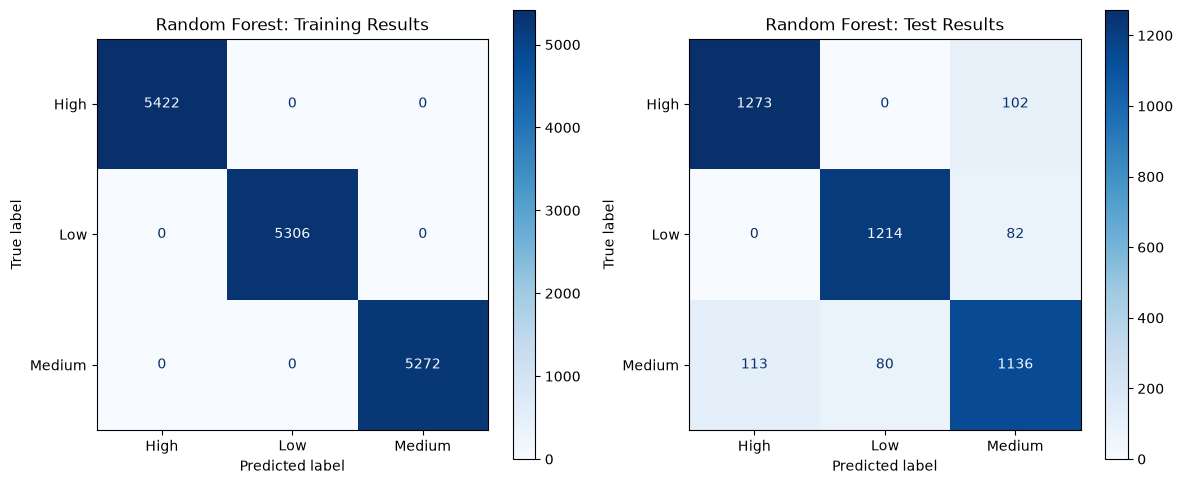

In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

labels = model["clf"].classes_

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train, train_predictions,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest: Training Results")

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Random Forest: Test Results")

plt.tight_layout()
plt.show()

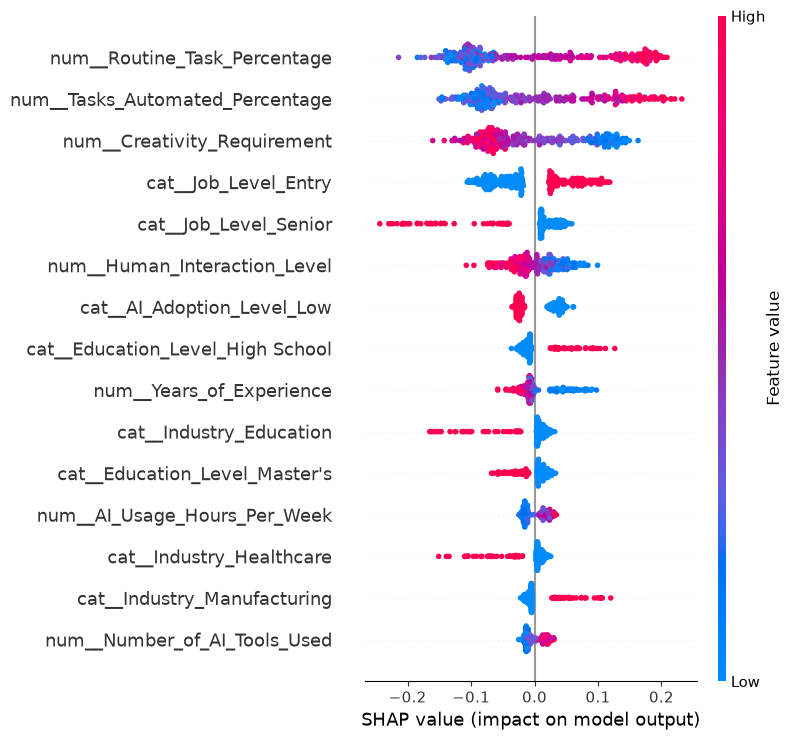

In [64]:
import shap
import pandas as pd

# Sample test profiles to keep the explanation manageable
X_shap_raw = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

# Transform profiles using the preprocessing already fit on training data
prep = model["prep"]
X_shap_transformed = prep.transform(X_shap_raw)

if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

X_shap = pd.DataFrame(
    X_shap_transformed,
    columns=prep.get_feature_names_out(),
    index=X_shap_raw.index
)

# Explain the fitted Random Forest
explainer = shap.TreeExplainer(model["clf"])
shap_values = explainer.shap_values(X_shap)

# Choose the risk category to explain
risk_category = "High"
class_index = list(model["clf"].classes_).index(risk_category)

# Select that category's SHAP values
if isinstance(shap_values, list):
    class_shap_values = shap_values[class_index]
else:
    class_shap_values = shap_values[:, :, class_index]

shap.summary_plot(
    class_shap_values,
    X_shap,
    max_display=15
)

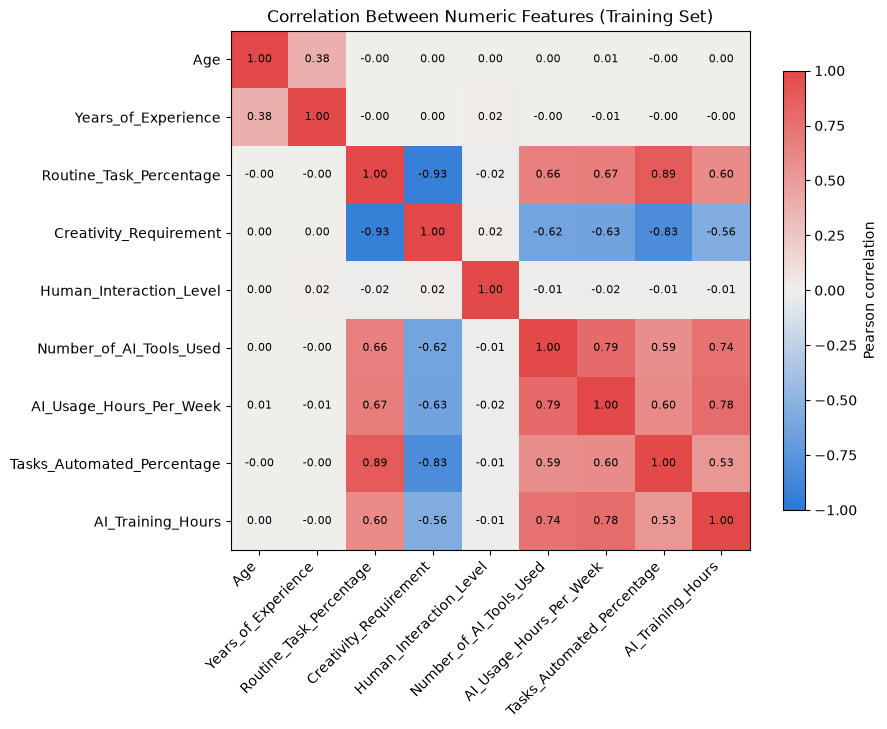

In [62]:
from matplotlib.colors import LinearSegmentedColormap

num_feats = list(num_cols)
corr_num = X_enc[num_feats].corr()

cmap = LinearSegmentedColormap.from_list(
    "div", ["#2a78d6", "#f0efec", "#e34948"]
)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_num, cmap=cmap, vmin=-1, vmax=1)

ax.set_xticks(range(len(num_feats)), num_feats, rotation=45, ha="right")
ax.set_yticks(range(len(num_feats)), num_feats)

for i in range(len(num_feats)):
    for j in range(len(num_feats)):
        ax.text(
            j, i, f"{corr_num.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation Between Numeric Features (Training Set)")
plt.tight_layout()
plt.show()

In [65]:
TRAIN, TEST = train_test_split(
    df,
    train_size=0.8,
    random_state=42,
    stratify=df["Layoff_Risk"]
)

In [66]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

TRAIN, TEST = train_test_split(
    df,
    train_size=0.8,
    random_state=42,
    stratify=df["Layoff_Risk"]
)

X_train = TRAIN.drop(columns="Layoff_Risk")
y_train = TRAIN["Layoff_Risk"]
X_test = TEST.drop(columns="Layoff_Risk")
y_test = TEST["Layoff_Risk"]

cat_cols = X_train.select_dtypes(include="str").columns
num_cols = X_train.select_dtypes(include="number").columns

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

log_model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])

rf_model = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

baseline = DummyClassifier(strategy="most_frequent")

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
baseline.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](3,)","[0.34,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](16,)","['Age','Education_Level','Years_of_Experience',..., 'Tasks_Automated_Percentage','AI_Training_Hours','Experience_Tier']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,16
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [67]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

models = {
    "Baseline": baseline,
    "Logistic Regression": log_model,
    "Random Forest": rf_model
}

results = []

for name, fitted_model in models.items():
    predictions = fitted_model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

display(pd.DataFrame(results).round(3))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Baseline,0.340,0.113,0.333,0.169
1,Logistic Regression,0.938,0.938,0.938,0.938
2,Random Forest,0.908,0.907,0.907,0.907


In [70]:
from scipy.stats import f_oneway

numeric_features = [
    "Age",
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Number_of_AI_Tools_Used",
    "AI_Usage_Hours_Per_Week",
    "Tasks_Automated_Percentage",
    "AI_Training_Hours"
]

risk_labels = ["Low", "Medium", "High"]
anova_results = []

for feature in numeric_features:
    groups = [
        df.loc[df["Layoff_Risk"] == risk, feature].dropna()
        for risk in risk_labels
    ]

    f_stat, p_value = f_oneway(*groups)

    anova_results.append({
        "Feature": feature,
        "F statistic": f_stat,
        "p-value": p_value
    })

anova_table = pd.DataFrame(anova_results)
anova_table["Adjusted p-value"] = (
    anova_table["p-value"] * len(numeric_features)
).clip(upper=1)

display(anova_table.round({
    "F statistic": 4,
    "p-value": 3,
    "Adjusted p-value": 3
}))

anova_table = pd.DataFrame(anova_results)
anova_table["Adjusted p-value"] = (
    anova_table["p-value"] * len(numeric_features)
).clip(upper=1)

display(anova_table.round(4))

,Feature,F statistic,p-value,Adjusted p-value
0,Age,13.6184,0.0,0.0
1,Years_of_Experience,102.2438,0.0,0.0
2,Routine_Task_Percentage,15645.3839,0.0,0.0
3,Number_of_AI_Tools_Used,3388.9945,0.0,0.0
4,AI_Usage_Hours_Per_Week,3492.8691,0.0,0.0
5,Tasks_Automated_Percentage,12776.8409,0.0,0.0
6,AI_Training_Hours,2339.5063,0.0,0.0


,Feature,F statistic,p-value,Adjusted p-value
0,Age,13.6184,0.0,0.0
1,Years_of_Experience,102.2438,0.0,0.0
2,Routine_Task_Percentage,15645.3839,0.0,0.0
3,Number_of_AI_Tools_Used,3388.9945,0.0,0.0
4,AI_Usage_Hours_Per_Week,3492.8691,0.0,0.0
5,Tasks_Automated_Percentage,12776.8409,0.0,0.0
6,AI_Training_Hours,2339.5063,0.0,0.0


In [71]:
rf_test_predictions = rf_model.predict(X_test)

role_results = pd.DataFrame({
    "Job_Role": TEST["Job_Role"],
    "Actual": y_test,
    "Predicted": rf_test_predictions
})

role_results["Correct"] = (
    role_results["Actual"] == role_results["Predicted"]
)

role_accuracy = (
    role_results.groupby("Job_Role")["Correct"]
    .mean()
    .mul(100)
    .sort_values()
)

display(role_accuracy.round(1).rename("Accuracy (%)"))

Job_Role
Production Supervisor    85.2
Academic Coordinator     85.4
Teacher                  86.7
Data Analyst             87.3
Sales Associate          88.0
Warehouse Manager        88.2
ML Engineer              88.8
Health Analyst           89.7
Operator                 89.8
Research Assistant       89.9
Medical Assistant        90.1
Supply Chain Analyst     90.4
Support Specialist       90.9
Dispatcher               90.9
Operations Analyst       92.0
Nurse                    92.7
Financial Analyst        93.4
Accountant               93.4
Software Engineer        93.7
Network Engineer         93.7
Store Manager            94.0
Inventory Analyst        94.2
Quality Engineer         94.4
Auditor                  94.8
Name: Accuracy (%), dtype: float64

In [73]:
rf_test_predictions = rf_model.predict(X_test)

role_results = pd.DataFrame({
    "Job_Level": TEST["Job_Level"],
    "Actual": y_test,
    "Predicted": rf_test_predictions
})

role_results["Correct"] = (
    role_results["Actual"] == role_results["Predicted"]
)

role_accuracy = (
    role_results.groupby("Job_Level")["Correct"]
    .mean()
    .mul(100)
    .sort_values()
)

display(role_accuracy.round(1).rename("Accuracy (%)"))

Job_Level
Entry     90.6
Senior    90.7
Mid       90.9
Name: Accuracy (%), dtype: float64

In [74]:
rf_test_predictions = rf_model.predict(X_test)

role_results = pd.DataFrame({
    "Education_Level": TEST["Education_Level"],
    "Actual": y_test,
    "Predicted": rf_test_predictions
})

role_results["Correct"] = (
    role_results["Actual"] == role_results["Predicted"]
)

role_accuracy = (
    role_results.groupby("Education_Level")["Correct"]
    .mean()
    .mul(100)
    .sort_values()
)

display(role_accuracy.round(1).rename("Accuracy (%)"))

Education_Level
PhD            82.7
High School    89.2
Master's       90.7
Bachelor's     92.2
Name: Accuracy (%), dtype: float64

In [76]:
rf_test_predictions = rf_model.predict(X_test)

role_results = pd.DataFrame({
    "Company_Size": TEST["Company_Size"],
    "Actual": y_test,
    "Predicted": rf_test_predictions
})

role_results["Correct"] = (
    role_results["Actual"] == role_results["Predicted"]
)

role_accuracy = (
    role_results.groupby("Company_Size")["Correct"]
    .mean()
    .mul(100)
    .sort_values()
)

display(role_accuracy.round(1).rename("Accuracy (%)"))

Company_Size
Small     90.3
Large     90.4
Medium    91.2
Name: Accuracy (%), dtype: float64

In [1]:
from sklearn.inspection import permutation_importance

results = permutation_importance(
    rf_model,       # your fitted Random Forest pipeline
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": results.importances_mean,
    "Variation": results.importances_std
}).sort_values("Importance", ascending=False)

display(importance.round(3))

NameError: name 'rf_model' is not defined